In [9]:
import pyuvdata
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from astropy.visualization import ZScaleInterval, ImageNormalize
import matplotlib.pyplot as plt 
import bdsf

In [10]:
fits_path = "/fast/rbyrne/20260419_084843-085034_34MHz_selfcal_peeled-dirty.fits"

In [11]:
img = bdsf.process_image(
    fits_path,
    thresh_pix = 10  # Default is 5, increase to get only the brightest sources
)

--> Opened '/fast/rbyrne/20260419_084843-085034_34MHz_selfcal_peeled-dirty.fits'
Image size .............................. : (4096, 4096) pixels
Number of channels ...................... : 1
Number of Stokes parameters ............. : 1
Beam shape (major, minor, pos angle) .... : (3.57396e-01, 2.38958e-01, 62.1) degrees
Frequency of image ...................... : 34.824 MHz
Number of blank pixels .................. : 0 (0.0%)


Flux from sum of (non-blank) pixels ..... : -9071.820 Jy
--> Calculating background rms and mean images
Derived rms_box (box size, step size) ... : (651, 217) pixels
--> Variation in rms image significant
--> Using 2D map for background rms
--> Variation in mean image significant
--> Using 2D map for background mean
Min/max values of background rms map .... : (1.02e+00, 5.73e+00) Jy/beam
Min/max values of background mean map ... : (-1.09e+00, 3.84e-01) Jy/beam
--> Expected 5-sigma-clipped false detection rate < fdr_ratio
--> Using sigma-clipping ('hard') thresholding
Minimum number of pixels per island ..... : 33
Number of islands found ................. : 397


Fitting islands with Gaussians .......... : [|] 0/397Fitting islands with Gaussians .......... : [\] 7/397Fitting islands with Gaussians .......... : [\] 7/397Fitting islands with Gaussians .......... : [/] 21/397Fitting islands with Gaussians .......... : [/] 25/397Fitting islands with Gaussians .......... : [-] 30/397Fitting islands with Gaussians .......... : [\] 31/397Fitting islands with Gaussians .......... : [\] 31/397Fitting islands with Gaussians .......... : [|] 28/397Fitting islands with Gaussians .......... : [\] 65/397Fitting islands with Gaussians .......... : [\] 69/397Fitting islands with Gaussians .......... : [\] 31/397Fitting islands with Gaussians .......... : [/] 75/397Fitting islands with Gaussians .......... : [\] 81/397Fitting islands with Gaussians .......... : [/] 117/397Fitting islands with Gaussians .......... : [/] 133/397Fitting islands with Gaussians .......... : [/] 137/397Fitting islands with Gaussians .......... : [-] 138/397Fitting islands with Gaussi

Total number of Gaussians fit to image .. : 570
Total flux density in model ............. : 33815.333 Jy
--> Grouping Gaussians into sources
Number of sources formed from Gaussians   : 477
    Island #357 (x=3281, y=3430): fit with 4 Gaussians with flags = 270, 270, 381, 269
Please check this island. If it is a valid island and
should be fit, try adjusting the flagging options (use
show_fit with "ch0_flagged=True" to see the flagged Gaussians
and "help 'flagging_opts'" to see the meaning of the flags)
or enabling the wavelet module (with "atrous_do=True").
To include empty islands in output source catalogs, set
incl_empty=True in the write_catalog task.


NOTE -- With the mouse pointer in plot window:
  Press "i" ........ : Get integrated flux densities and mean rms
                       values for the visible portion of the image
  Press "m" ........ : Change min and max scaling values
  Press "n" ........ : Show / hide island IDs
  Press "0" ........ : Reset scaling to default
  Click Gaussian ... : Print Gaussian and source IDs (zoom_rect mode, 
                       toggled with the "zoom" button and indicated in 
                       the lower right corner, must be off)
________________________________________________________________________


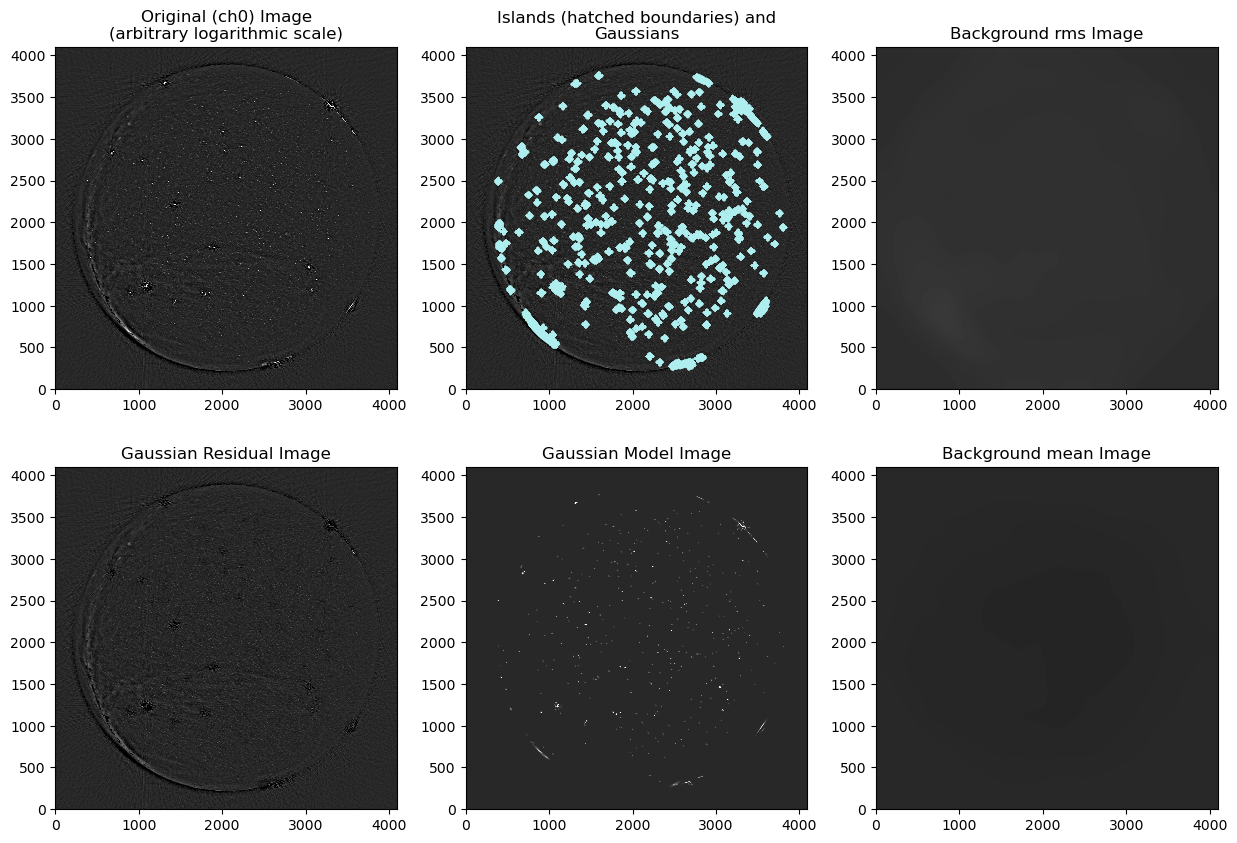

True

In [12]:
img.show_fit()

In [13]:
with fits.open(fits_path) as hdul:
    data = hdul[0].data.squeeze()
    header = hdul[0].header

In [14]:
def get_pixel_az_za(x_pix, y_pix, header):

    wcs_cel = WCS(header).celestial
    ny, nx = header['NAXIS2'], header['NAXIS1']

    crpix1, crpix2 = header['CRPIX1'] - 1, header['CRPIX2'] - 1
    cd = wcs_cel.pixel_scale_matrix

    y_idx, x_idx = np.mgrid[0:ny, 0:nx]
    dx = x_pix - crpix1
    dy = y_pix - crpix2
    xi  = cd[0, 0]*dx + cd[0, 1]*dy
    eta = cd[1, 0]*dx + cd[1, 1]*dy

    az = np.degrees(np.arctan2(eta, -xi)) % 360.0

    R = 180.0 / np.pi
    r = np.sqrt(xi**2 + eta**2)
    za = np.degrees(np.arcsin(r * np.pi / 180))

    return az, za

In [15]:
x_pixels = np.full(len(img.gaussians), np.nan)
y_pixels = np.full(len(img.gaussians), np.nan)
total_flux = np.full(len(img.gaussians), np.nan)
for source_ind, source in enumerate(img.gaussians):
    x_pixels[source_ind] = source.centre_pix[0]
    y_pixels[source_ind] = source.centre_pix[1]
    total_flux[source_ind] = source.total_flux

In [23]:
img.gaussians[0].__dict__

{'gaussian_idx': 0,
 'gaus_num': 0,
 'island_id': 0,
 'jlevel': 0,
 'flag': 0,
 'parameters': [83.2498731457959,
  386.3840817972285,
  2497.6500795940324,
  4.85294206583516,
  4.151336188744839,
  104.2266587657075],
 'peak_flux': 83.2498731457959,
 'centre_pix': [386.3840817972285, 2497.6500795940324],
 'size_pix': [11.427805035469952, 9.775649483980123, 14.226658765707498],
 'centre_sky': [-56.51117059151291, 23.81800006176545],
 'centre_skyE': (0.012879818797088265, 0.006083914003418223),
 'size_sky': (0.8874391089093502,
  0.3574583550956413,
  np.float64(131.98867146942916)),
 'size_sky_uncorr': [0.357118907358436,
  0.30548904637437885,
  14.226658765707498],
 'size_skyE': (0.013742756759255357,
  0.02810059196345566,
  np.float32(8.236427)),
 'size_skyE_uncorr': [np.float32(0.013056765),
  np.float32(0.009737468),
  np.float32(8.236427)],
 'deconv_size_sky': (0.0, 0.0, 0.0),
 'deconv_size_sky_uncorr': [0.0, 0.0, 0.0],
 'deconv_size_skyE': (0.013742756759255357,
  0.02810059196

In [16]:
az_vals, za_vals = get_pixel_az_za(x_pixels, y_pixels, header)

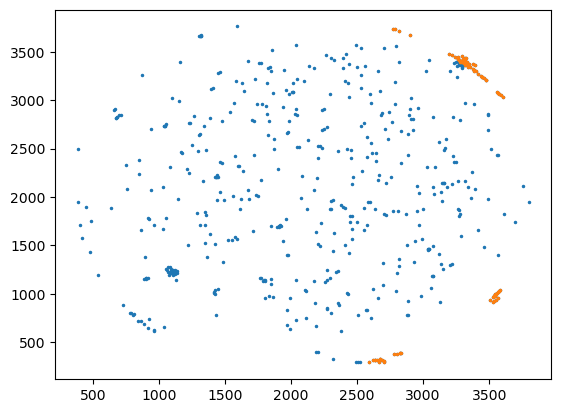

In [17]:
horizon_source_inds = np.where((za_vals > 85) + ~np.isfinite(za_vals))
plt.plot(x_pixels, y_pixels, ".", markersize=3)
plt.plot(x_pixels[horizon_source_inds], y_pixels[horizon_source_inds], ".", markersize=3)

In [19]:
len(horizon_source_inds[0])

94